Name: Atharva Dhale

Roll No: C4-59

ML LAB 8


First five rows:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    

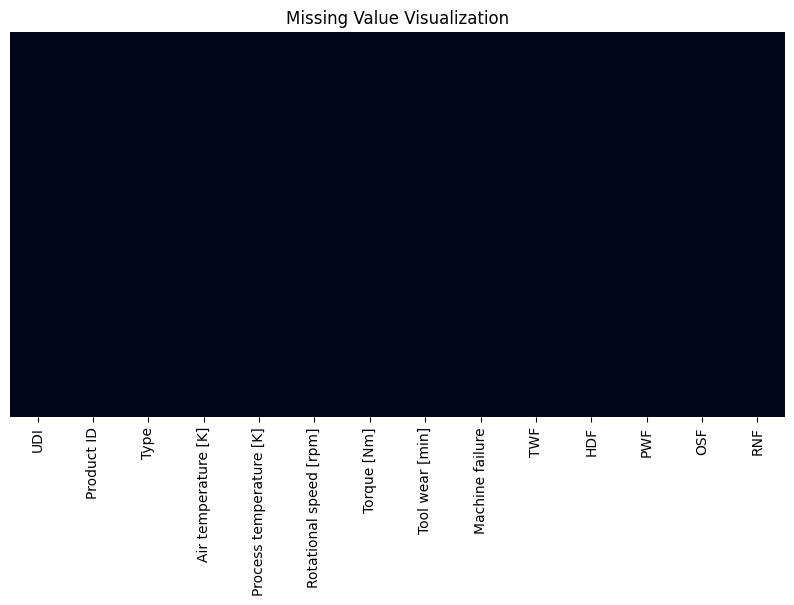


Input shape: (10000, 6)
Output shape: (10000,)

========== LINEAR SVM ==========
Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



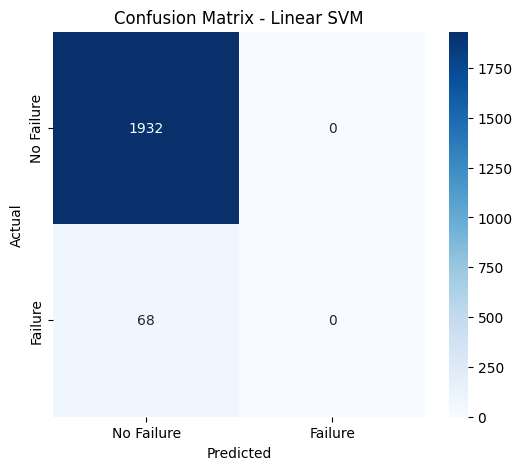


========== RBF SVM ==========
Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1-score: 0.3333333333333333

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



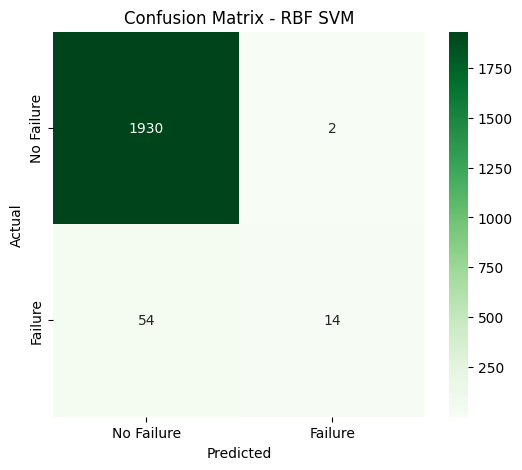


========== MODEL COMPARISON ==========
           Linear SVM   RBF SVM
Accuracy        0.966  0.972000
Precision       0.000  0.875000
Recall          0.000  0.205882
F1-score        0.000  0.333333
Fitting 5 folds for each of 14 candidates, totalling 70 fits

========== GRID SEARCH RESULTS ==========
GridSearchCV completed.
Best parameters found:
{'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best F1-score:
0.6538878032893665


In [7]:
# LAB 8: SUPPORT VECTOR MACHINE (SVM) CLASSIFICATION

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")


# 2. Load dataset
df = pd.read_csv("ai4i2020 - ai4i2020.csv")


# 3. Explore dataset
print("First five rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical description:")
print(df.describe())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nColumn names:")
print(df.columns)

print("\nTransposed description:")
print(df.describe().T)


# 4. Visualize missing values
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Value Visualization")
plt.show()


# 5. Select input features and target
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

y = df["Machine failure"]

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)


# 6. Define categorical and numerical features
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]


# 7. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 8. Preprocess the data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


# 9. Build and train Linear SVM
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)

linear_svm.fit(X_train, y_train)

y_pred_linear = linear_svm.predict(X_test)


# 10. Evaluate Linear SVM
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(
    y_test, y_pred_linear, zero_division=0
)
recall_linear = recall_score(
    y_test, y_pred_linear, zero_division=0
)
f1_linear = f1_score(
    y_test, y_pred_linear, zero_division=0
)

print("\n========== LINEAR SVM ==========")
print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1-score:", f1_linear)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)


# 11. Confusion matrix for Linear SVM
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")
plt.show()


# 12. Build and train RBF SVM
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)

rbf_svm.fit(X_train, y_train)

y_pred_rbf = rbf_svm.predict(X_test)


# 13. Evaluate RBF SVM
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(
    y_test, y_pred_rbf, zero_division=0
)
recall_rbf = recall_score(
    y_test, y_pred_rbf, zero_division=0
)
f1_rbf = f1_score(
    y_test, y_pred_rbf, zero_division=0
)

print("\n========== RBF SVM ==========")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1-score:", f1_rbf)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)


# 14. Confusion matrix for RBF SVM
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")
plt.show()


# 15. Compare both models
comparison = pd.DataFrame(
    {
        "Linear SVM": [
            accuracy_linear,
            precision_linear,
            recall_linear,
            f1_linear
        ],
        "RBF SVM": [
            accuracy_rbf,
            precision_rbf,
            recall_rbf,
            f1_rbf
        ]
    },
    index=["Accuracy", "Precision", "Recall", "F1-score"]
)

print("\n========== MODEL COMPARISON ==========")
print(comparison)


# 16. Create pipeline for hyperparameter tuning
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC())
    ]
)


# 17. Define hyperparameter grid
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]


# 18. Perform GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    verbose=1,
    n_jobs=-1,
    scoring="f1"
)

grid_search.fit(X_train, y_train)


# 19. Display best parameters and score
print("\n========== GRID SEARCH RESULTS ==========")
print("GridSearchCV completed.")

print("Best parameters found:")
print(grid_search.best_params_)

print("Best F1-score:")
print(grid_search.best_score_)